# DATA 4381 - CAPSTONE - FER-2013

## Neural Network Baseline - Augmentation Comparison

### Overview

This notebook will evaluate our neural network build from scratch using NumPy. This notebook will focus on solving our primary issue of data imbalance across the FER-2013 dataset. To do so we implemented several forms of data augmentation and we will compare the results here.

### Classification Task

Our model predicts three facial expressions (compared to four in our original baseline):

- Angry (0)
- Happy (1)
- Sad (2)
  NOTE: Neutral was dropped (in similar guidance to Microsoft research team)

### Neural Network Architecture

This network uses a fully connected feedforward:

1. Input: 48x48 grayscale image
2. Flatten: 2,304 input features
3. Dense layer: 128 neurons
4. ReLU activation
5. Output layer: 3 neurons
6. Softmax probabilities for classification

The model is trained using categorical cross-entropy loss with integer-encoded labels and mini-batch gradient descent.


### 1.3 Experimental Design

We treat Augmentation V1 and Augmentation V3 as separate
experiments using our NumPy neural-network baseline.

Each experiment uses its own predefined training,
validation, and test partitions.

To maintain consistency, both experiments use the same:

- Neural network architecture
- Weight initialization procedure
- Learning rate and optimizer
- Batch size
- Number of training epochs

The primary objective is to evaluate the baseline's
performance on each dataset configuration independently.

Because the validation and test partitions differ,
performance differences cannot be attributed exclusively
to the augmentation strategy.

### Data Leakage Prevention

Within each experiment, we must ensure that training,
validation, and test images remain independent.

We will first check for exact image-content overlap
between partitions. We will then investigate potential
near-duplicate or augmented-source leakage before training.


# -----------------------------------------------------------

In [1]:
# imports and environment verification

from pathlib import Path
import sys
import inspect
import numpy as np

import capstone_data.image_loader as loader

from capstone_nn.model import Sequential
from capstone_nn.layers import Flatten, Dense
from capstone_nn.activations import ReLU
from capstone_nn.training import train_epoch, evaluate

# Verify Python environment
print("Python executable:", sys.executable)

# Verify project directories
print("\nProject root:", loader.ROOT)
print("Data directory:", loader.DATA_DIR)

# Verify emotion classes
print("\nClasses:", loader.CLASS_NAMES)
print("Class labels:", loader.CLASS_TO_INDEX)

# Verify available datasets
print("\nAvailable datasets:")

for name, path in loader.list_datasets().items():
    print(f"  {name}: {path}")

# Verify that our updated loader supports split selection
print("\nLoader signature:")
print(inspect.signature(loader.load_dataset))


Python executable: C:\Users\mashe\miniconda3\envs\DATA4380\python.exe

Project root: C:\Users\mashe\code\class\Capstone-DATA4381
Data directory: C:\Users\mashe\code\class\Capstone-DATA4381\data

Classes: ('angry', 'happy', 'sad')
Class labels: {'angry': 0, 'happy': 1, 'sad': 2}

Available datasets:
  final: C:\Users\mashe\code\class\Capstone-DATA4381\data\final
  aug_data_v1: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v1
  aug_data_v3: C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3

Loader signature:
(datasets='final', split=None)



## 1. Dataset Loading and Integrity Verification

### 1.1 Loading the Experimental Datasets

This notebook evaluates our NumPy neural-network baseline using two independently prepared versions of the FER-2013 dataset: Augmentation V1 and Augmentation V3.

Each dataset contains three predefined partitions:

- **Training:** Used to optimize the neural network's parameters.
- **Validation:** Used to monitor generalization and guide model selection.
- **Testing:** Reserved for final evaluation.

We load each dataset using our `capstone_data` package without performing additional random splitting.

### Experimental Design

V1 and V3 are treated as **independent experiments**, each using its own training, validation, and test partitions.

Both experiments use the same neural-network architecture, initialization procedure, and training hyperparameters.

Because their evaluation partitions differ, differences in performance cannot be attributed exclusively to augmentation.

### Data Integrity

Before training, we will:

- Examine the class distributions of each dataset.
- Verify image dimensions and class labels.
- Check for exact duplicate images across partitions.
- Investigate potential near-duplicate and augmentation-related leakage.

These checks help establish whether each dataset is suitable for independent model evaluation.


In [2]:

# Define our experiments
versions = ("aug_data_v1", "aug_data_v3")
splits = ("train", "validation", "test")

# Load all six existing partitions
datasets = {}

for version in versions:
    datasets[version] = {}

    for split in splits:
        datasets[version][split] = loader.load_dataset(
            version,
            split=split
        )

        print(
            f"{version} / {split}: "
            f"{len(datasets[version][split]):,} images"
        )

print("\nLoaded dataset keys:", list(datasets.keys()))


aug_data_v1 / train: 14,019 images
aug_data_v1 / validation: 1,662 images
aug_data_v1 / test: 1,673 images
aug_data_v3 / train: 12,047 images
aug_data_v3 / validation: 1,650 images
aug_data_v3 / test: 1,646 images

Loaded dataset keys: ['aug_data_v1', 'aug_data_v3']


In [3]:

import hashlib
from PIL import Image

# Generate a fingerprint from an image's pixel contents
def fingerprint(record):

    with Image.open(record["path"]) as image:
        gray = image.convert("L")

        digest = hashlib.sha256()
        digest.update(str(gray.size).encode())
        digest.update(gray.tobytes())

    return digest.hexdigest()

# Check each experiment independently
for version in versions:

    print(f"\n{version.upper()} — LEAKAGE CHECK")
    print("=" * 50)

    # Store unique image hashes for each partition
    hashes = {}

    for split in splits:

        records = datasets[version][split]

        hashes[split] = {
            fingerprint(record)
            for record in records
        }

        print(
            f"{split:<12}: "
            f"{len(records):,} images, "
            f"{len(hashes[split]):,} unique hashes"
        )

    # Compare image contents across partitions
    overlaps = {
        "Train / Validation":
            hashes["train"] & hashes["validation"],

        "Train / Test":
            hashes["train"] & hashes["test"],

        "Validation / Test":
            hashes["validation"] & hashes["test"],
    }

    print("\nCross-partition overlap:")

    for comparison, shared in overlaps.items():
        print(f"{comparison:<22}: {len(shared)}")

    if all(len(shared) == 0 for shared in overlaps.values()):
        print("\nPASS: No exact pixel overlap detected.")
    else:
        print("\nWARNING: Exact pixel overlap detected.")



AUG_DATA_V1 — LEAKAGE CHECK
train       : 14,019 images, 13,721 unique hashes
validation  : 1,662 images, 1,644 unique hashes
test        : 1,673 images, 1,643 unique hashes

Cross-partition overlap:
Train / Validation    : 18
Train / Test          : 21
Validation / Test     : 1


AUG_DATA_V3 — LEAKAGE CHECK
train       : 12,047 images, 11,467 unique hashes
validation  : 1,650 images, 1,644 unique hashes
test        : 1,646 images, 1,643 unique hashes

Cross-partition overlap:
Train / Validation    : 12
Train / Test          : 17
Validation / Test     : 1



In [4]:

# Compare unique image contents across dataset versions.

for split in ("validation", "test"):

    v1_hashes = {
        fingerprint(record)
        for record in datasets["aug_data_v1"][split]
    }

    v3_hashes = {
        fingerprint(record)
        for record in datasets["aug_data_v3"][split]
    }

    print(f"\n{split.upper()}")
    print("=" * 40)

    print("V1 unique:", len(v1_hashes))
    print("V3 unique:", len(v3_hashes))

    print("Shared:", len(v1_hashes & v3_hashes))
    print("V1 only:", len(v1_hashes - v3_hashes))
    print("V3 only:", len(v3_hashes - v1_hashes))

    print("Same unique images:", v1_hashes == v3_hashes)



VALIDATION
V1 unique: 1644
V3 unique: 1644
Shared: 1644
V1 only: 0
V3 only: 0
Same unique images: True

TEST
V1 unique: 1643
V3 unique: 1643
Shared: 1643
V1 only: 0
V3 only: 0
Same unique images: True



### 1.5 Investigating Duplicate Images

Both augmentation versions contain identical sets of unique
validation and test image contents, despite having different
numbers of total images.

Our audit also identified exact image overlap between
training and evaluation partitions.

We will inspect the filenames and class labels of overlapping
images to investigate their origin.

No dataset files will be modified during this investigation.


In [5]:

from collections import defaultdict


def group_by_hash(records):
    """Group image records by their pixel fingerprint."""

    groups = defaultdict(list)

    for record in records:
        image_hash = fingerprint(record)
        groups[image_hash].append(record)

    return groups


for version in versions:

    print(f"\n{version.upper()}")
    print("=" * 55)

    # Build hash-to-record mappings for all partitions.
    groups = {
        split: group_by_hash(datasets[version][split])
        for split in splits
    }

    # Examine duplicates within evaluation partitions.
    for split in ("validation", "test"):

        duplicates = {
            h: records
            for h, records in groups[split].items()
            if len(records) > 1
        }

        extra_copies = sum(
            len(records) - 1
            for records in duplicates.values()
        )

        print(f"\n{split.upper()} DUPLICATES")
        print("Duplicate groups:", len(duplicates))
        print("Extra copies:", extra_copies)

    # Examine training/evaluation overlap.
    for split in ("validation", "test"):

        shared = (
            groups["train"].keys()
            & groups[split].keys()
        )

        print(f"\nTRAIN / {split.upper()} OVERLAP")
        print("Matching hashes:", len(shared))

        # Display three examples without overwhelming output.
        for image_hash in sorted(shared)[:3]:

            print("\n  Training files:")

            for record in groups["train"][image_hash][:3]:
                print(
                    "   ",
                    record["class_name"],
                    record["path"].name
                )

            print(f"  {split.capitalize()} files:")

            for record in groups[split][image_hash][:3]:
                print(
                    "   ",
                    record["class_name"],
                    record["path"].name
                )



AUG_DATA_V1

VALIDATION DUPLICATES
Duplicate groups: 18
Extra copies: 18

TEST DUPLICATES
Duplicate groups: 30
Extra copies: 30

TRAIN / VALIDATION OVERLAP
Matching hashes: 18

  Training files:
    angry original_001221.jpg
  Validation files:
    angry original_000391.jpg

  Training files:
    happy original_001602.jpg
  Validation files:
    happy original_000070.jpg

  Training files:
    happy original_004652.jpg
  Validation files:
    happy original_000923.jpg

TRAIN / TEST OVERLAP
Matching hashes: 21

  Training files:
    angry original_000503.jpg
  Test files:
    angry original_000355.jpg

  Training files:
    angry original_000101.jpg
  Test files:
    angry original_000433.jpg

  Training files:
    happy original_002419.jpg
  Test files:
    happy original_000228.jpg

AUG_DATA_V3

VALIDATION DUPLICATES
Duplicate groups: 6
Extra copies: 6

TEST DUPLICATES
Duplicate groups: 3
Extra copies: 3

TRAIN / VALIDATION OVERLAP
Matching hashes: 12

  Training files:
    angry ori

In [6]:

from collections import Counter

for version in versions:

    print(f"\n{version.upper()}")
    print("=" * 50)

    # Group images by their pixel fingerprints
    groups = {
        split: group_by_hash(datasets[version][split])
        for split in splits
    }

    for left, right in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    ]:

        shared = groups[left].keys() & groups[right].keys()

        image_types = Counter()
        label_conflicts = 0

        for image_hash in shared:

            left_records = groups[left][image_hash]
            right_records = groups[right][image_hash]

            # Check filenames on both sides
            names = [
                record["path"].name.lower()
                for record in left_records + right_records
            ]

            if all(name.startswith("original_") for name in names):
                image_types["Original only"] += 1
            elif any(name.startswith("augmented_") for name in names):
                image_types["Includes augmented"] += 1
            else:
                image_types["Other filenames"] += 1

            # Check whether identical images have conflicting labels
            labels = {
                record["class_name"]
                for record in left_records + right_records
            }

            if len(labels) > 1:
                label_conflicts += 1

        print(f"\n{left} / {right}")
        print("Overlapping hashes:", len(shared))
        print("Image types:", dict(image_types))
        print("Conflicting labels:", label_conflicts)



AUG_DATA_V1

train / validation
Overlapping hashes: 18
Image types: {'Original only': 18}
Conflicting labels: 0

train / test
Overlapping hashes: 21
Image types: {'Original only': 21}
Conflicting labels: 0

validation / test
Overlapping hashes: 1
Image types: {'Original only': 1}
Conflicting labels: 0

AUG_DATA_V3

train / validation
Overlapping hashes: 12
Image types: {'Original only': 12}
Conflicting labels: 0

train / test
Overlapping hashes: 17
Image types: {'Original only': 17}
Conflicting labels: 0

validation / test
Overlapping hashes: 1
Image types: {'Original only': 1}
Conflicting labels: 0



### 1.6 Preparing Evaluation Partitions

The duplicate audit identified exact pixel overlap between
training, validation, and test partitions.

For exploratory experiments, we construct evaluation
partitions by:

1. Retaining one copy of each unique evaluation image.
2. Excluding images that appear in either training dataset.
3. Ensuring validation and test contain no shared images.
4. Preserving the original class labels.

The augmented training datasets remain unchanged.

These corrected evaluation partitions are used for
exploratory baseline assessment. A source-level,
duplicate-aware split is required for final reporting.


In [7]:

def unique_by_hash(records):
    """Retain one record per unique image content."""

    unique = {}

    for record in records:
        image_hash = fingerprint(record)

        if image_hash in unique:
            if unique[image_hash]["label"] != record["label"]:
                raise ValueError("Conflicting labels detected.")

        else:
            unique[image_hash] = record

    return unique


# Confirm V1 and V3 holdout images have identical labels.
for split in ("validation", "test"):

    v1 = unique_by_hash(datasets["aug_data_v1"][split])
    v3 = unique_by_hash(datasets["aug_data_v3"][split])

    v1_labels = {h: r["label"] for h, r in v1.items()}
    v3_labels = {h: r["label"] for h, r in v3.items()}

    if v1_labels != v3_labels:
        raise ValueError(
            f"V1 and V3 differ in {split} images or labels."
        )


# Collect every exact pixel hash used for training.
train_hashes = {
    fingerprint(record)
    for version in versions
    for record in datasets[version]["train"]
}

# Start with the shared unique evaluation images.
val_candidates = unique_by_hash(
    datasets["aug_data_v1"]["validation"]
)

test_candidates = unique_by_hash(
    datasets["aug_data_v1"]["test"]
)

# Exclude anything that appears in either training set.
clean_val = [
    record
    for h, record in val_candidates.items()
    if h not in train_hashes
]

clean_val_hashes = {
    fingerprint(record) for record in clean_val
}

# Also prevent validation/test overlap.
clean_test = [
    record
    for h, record in test_candidates.items()
    if h not in train_hashes
    and h not in clean_val_hashes
]

# Verify the resulting partitions.
assert all(
    fingerprint(record) not in train_hashes
    for record in clean_val + clean_test
)

assert not (
    clean_val_hashes
    & {fingerprint(record) for record in clean_test}
)

for name, records in [
    ("Validation", clean_val),
    ("Test", clean_test),
]:
    print(f"\n{name}: {len(records):,} images")

    counts = loader.count_images_by_class(records)

    for class_name in loader.CLASS_NAMES:
        print(f"  {class_name:<8}: {counts[class_name]:,}")

print("\nExact-overlap checks passed.")
print("Original dataset files were not modified.")



Validation: 1,626 images
  angry   : 454
  happy   : 992
  sad     : 180

Test: 1,621 images
  angry   : 451
  happy   : 989
  sad     : 181

Exact-overlap checks passed.
Original dataset files were not modified.



## 2. Data Preparation

### 2.1 Image Dimension Verification

Our neural-network baseline expects grayscale images with
dimensions of 48 × 48 pixels.

Before converting the datasets into NumPy arrays, we verify
that all images have the expected dimensions.

We examine:

- Augmentation V1 training images
- Augmentation V3 training images
- Cleaned validation images
- Cleaned test images

This check is particularly important because geometric
augmentation operations, such as rotation, can alter image
dimensions.

Any unexpected dimensions will be investigated before
training.

### 2.2 Normalization

After dimension verification, images will be converted to
NumPy arrays and normalized to the interval [0, 1] by
dividing pixel intensities by 255.

The model will receive arrays of shape:

- Images: (N, 48, 48)
- Labels: (N,)

Each image will subsequently be flattened into 2,304
features by our neural network's Flatten layer.


In [8]:

from collections import Counter
from PIL import Image

# Datasets we will use for training and evaluation
image_groups = {
    "V1 Training": datasets["aug_data_v1"]["train"],
    "V3 Training": datasets["aug_data_v3"]["train"],
    "Validation": clean_val,
    "Test": clean_test,
}

expected_size = (48, 48)

for name, records in image_groups.items():

    sizes = Counter()
    unexpected = []

    for record in records:

        with Image.open(record["path"]) as image:
            size = image.size

        sizes[size] += 1

        if size != expected_size and len(unexpected) < 3:
            unexpected.append(record["path"])

    print(f"\n{name}")
    print("=" * 40)

    for size, count in sorted(sizes.items()):
        print(f"{size}: {count:,} images")

    if not unexpected:
        print("PASS: All images are 48x48.")
    else:
        print("WARNING: Unexpected image dimensions.")

        for path in unexpected:
            print(" ", path)



V1 Training
(48, 48): 14,019 images
PASS: All images are 48x48.

V3 Training
(48, 48): 7,356 images
(50, 50): 924 images
(52, 52): 936 images
(54, 54): 989 images
(56, 56): 1,025 images
(58, 58): 817 images
  C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3\angry\train\augmented_00000.jpg
  C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3\angry\train\augmented_00001.jpg
  C:\Users\mashe\code\class\Capstone-DATA4381\data\augmented_data\aug_data_v3\angry\train\augmented_00003.jpg

Validation
(48, 48): 1,626 images
PASS: All images are 48x48.

Test
(48, 48): 1,621 images
PASS: All images are 48x48.



### 2.3 Handling Inconsistent Image Dimensions

Our dimension audit identified images larger than 48 × 48
pixels in the V3 training partition.

This is consistent with rotation augmentation using
an expanded image canvas.

To maintain compatibility with our neural network,
we added optional resizing to the `capstone_data`
image loader.

For V3, oversized images are resized to 48 × 48 using
bilinear interpolation during loading. V1 and the
evaluation partitions retain their original dimensions.

This preprocessing occurs in memory and does not
modify the underlying image files.

For final experiments, resizing should ideally be
standardized within the augmentation pipeline itself.


In [9]:
import importlib
import capstone_data.image_loader as loader

importlib.reload(loader)

<module 'capstone_data.image_loader' from 'C:\\Users\\mashe\\code\\class\\Capstone-DATA4381\\capstone_data\\image_loader.py'>

In [10]:
from pathlib import Path

loader_file = Path(
    r"C:\Users\mashe\code\class\Capstone-DATA4381"
    r"\capstone_data\image_loader.py"
)

lines = loader_file.read_text(
    encoding="utf-8"
).splitlines()

print(
    "\n".join(
        lines[540:565]
    )
)


    path = Path(path)

    with Image.open(path) as image:
        
        image = image.convert("L")

        if image.size != (48,48):

            if resize:
                image = image.resize(
                        (48,48),
                        resample=Image.Resampling.BILINEAR,
                )

            else:
                raise ValueError(
                        f"Expected 48x48 image, "
                        f"but got {image.size}: {path}"
                )


        image_array = np.asarray(
                image,
                dtype=np.float32,


In [11]:
import importlib
import capstone_data.image_loader as loader

loader = importlib.reload(loader)

print("Reloaded from:")
print(loader.__file__)

Reloaded from:
C:\Users\mashe\code\class\Capstone-DATA4381\capstone_data\image_loader.py


In [12]:

import importlib
from PIL import Image

# Reload our updated image loader
importlib.reload(loader)

# Find an oversized V3 training image
sample = None

for record in datasets["aug_data_v3"]["train"]:

    with Image.open(record["path"]) as image:
        if image.size != (48, 48):
            sample = record
            print("Original size:", image.size)
            break

if sample is None:
    raise ValueError("No oversized V3 image found.")

# Load and resize the image in memory
image_array = loader.load_image(
    sample["path"],
    resize=True,
)

print("Loaded shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum value:", image_array.min())
print("Maximum value:", image_array.max())


Original size: (54, 54)
Loaded shape: (48, 48)
Data type: float32
Minimum value: 0.0
Maximum value: 0.99215686



### 2.4 Converting Images to NumPy Arrays

We convert both augmented training datasets and our
cleaned validation partition into NumPy arrays using
the `capstone_data.load_arrays()` function.

V1 images already satisfy the required 48 × 48 dimensions.

V3 images are resized to 48 × 48 when necessary using
bilinear interpolation.

Pixel intensities are normalized to the interval [0, 1]
and stored as 32-bit floating-point values.

Each dataset produces:

- **X:** Image array with shape (N, 48, 48)
- **y:** Integer class labels with shape (N,)

We reserve the test partition for final evaluation.

These experiments remain exploratory because exact-duplicate
cleanup does not eliminate all possible near-duplicate leakage.


In [13]:

# Load V1 training data
X_train_v1, y_train_v1 = loader.load_arrays(
    datasets["aug_data_v1"]["train"]
)

# Load V3 training data
# Oversized images are resized in memory.
X_train_v3, y_train_v3 = loader.load_arrays(
    datasets["aug_data_v3"]["train"],
    resize=True
)

# Load our cleaned validation partition
X_val, y_val = loader.load_arrays(clean_val)

# Verify array shapes and normalization
arrays = {
    "V1 Training": (X_train_v1, y_train_v1),
    "V3 Training": (X_train_v3, y_train_v3),
    "Validation": (X_val, y_val),
}

for name, (X, y) in arrays.items():

    print(f"\n{name}")
    print("=" * 40)

    print("X shape:", X.shape)
    print("y shape:", y.shape)
    print("Data type:", X.dtype)
    print("Pixel range:", X.min(), "to", X.max())

    assert X.shape == (len(y), 48, 48)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0
    assert X.max() <= 1.0

print("\nAll NumPy arrays loaded successfully.")


Loading images nerds:   0%|          | 0/14019 [00:00<?, ?it/s]

Loading images nerds:   0%|          | 0/12047 [00:00<?, ?it/s]

Loading images nerds:   0%|          | 0/1626 [00:00<?, ?it/s]


V1 Training
X shape: (14019, 48, 48)
y shape: (14019,)
Data type: float32
Pixel range: 0.0 to 1.0

V3 Training
X shape: (12047, 48, 48)
y shape: (12047,)
Data type: float32
Pixel range: 0.0 to 1.0

Validation
X shape: (1626, 48, 48)
y shape: (1626,)
Data type: float32
Pixel range: 0.0 to 1.0

All NumPy arrays loaded successfully.



## 3. Neural Network Architecture

### 3.1 Baseline Model Initialization

We use our custom `capstone_nn` package to construct a fully
connected feedforward neural network from scratch using NumPy.

The architecture consists of:

1. **Flatten:** Converts each 48 × 48 image into 2,304 features.
2. **Dense(2304, 128):** Maps input features to 128 hidden neurons.
3. **ReLU:** Introduces nonlinearity.
4. **Dense(128, 3):** Produces three output scores (logits).

Softmax converts the logits into class probabilities during
training and evaluation.

We initialize model weights with a fixed random seed to
support reproducibility and consistent initialization
between V1 and V3 experiments.

Before training, we verify the model's output dimensions
and probability calculations.


In [14]:

from capstone_nn.losses import softmax

# Construct our baseline neural network.
def build_baseline(seed=42):

    # Dense layers use NumPy's global random generator.
    np.random.seed(seed)

    model = Sequential(
        Flatten(),
        Dense(2304, 128),
        ReLU(),
        Dense(128, 3),
    )

    return model


# Initialize our first model.
model_v1 = build_baseline(seed=42)

# Select eight training images for a forward-pass test.
X_sample = X_train_v1[:8]

# Compute raw output scores (logits).
logits = model_v1.forward(X_sample)

# Convert logits into probabilities.
probabilities = softmax(logits)

print("Input shape:", X_sample.shape)
print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)

print("\nFirst image probabilities:")
for class_name, probability in zip(
    loader.CLASS_NAMES,
    probabilities[0],
):
    print(f"{class_name:<8}: {probability:.4f}")

print("\nProbability sum:", probabilities[0].sum())

# Verify output properties.
assert logits.shape == (8, 3)
assert np.isfinite(probabilities).all()

np.testing.assert_allclose(
    probabilities.sum(axis=1),
    np.ones(8),
    atol=1e-6,
)

print("\nForward-pass checks passed.")


Input shape: (8, 48, 48)
Logits shape: (8, 3)
Probabilities shape: (8, 3)

First image probabilities:
angry   : 0.6416
happy   : 0.1017
sad     : 0.2567

Probability sum: 1.0

Forward-pass checks passed.



### 3.2 Model Parameters and Reproducibility

Our baseline contains two fully connected layers with
trainable weights and biases.

For a dense layer, the number of trainable parameters is:

\[
\text{Parameters} = (n_{\text{input}} \times n_{\text{output}}) + n_{\text{output}}
\]

The Flatten and ReLU layers contain no trainable parameters.

To ensure consistent experimental conditions, we initialize
separate models for V1 and V3 using the same random seed.

This ensures both experiments begin with identical weights
and biases, allowing us to examine how training on different
dataset configurations affects the resulting models.

The two models maintain independent parameters during training.


In [15]:

# Initialize V3 with the same seed as V1.
model_v3 = build_baseline(seed=42)

# Inspect trainable parameters.
total_parameters = 0

print("BASELINE MODEL PARAMETERS")
print("=" * 50)

for index, layer in enumerate(model_v1.layers):

    layer_name = type(layer).__name__

    if isinstance(layer, Dense):

        weights = layer.weights.size
        biases = layer.bias.size

        parameters = weights + biases
        total_parameters += parameters

        print(f"\nLayer {index}: {layer_name}")
        print("Weights shape:", layer.weights.shape)
        print("Bias shape:", layer.bias.shape)
        print("Parameters:", f"{parameters:,}")

    else:
        print(f"\nLayer {index}: {layer_name}")
        print("Parameters: 0")

print("\nTotal trainable parameters:",
      f"{total_parameters:,}")


# Verify identical initialization.
for layer_v1, layer_v3 in zip(
    model_v1.layers,
    model_v3.layers,
):

    if isinstance(layer_v1, Dense):

        assert np.array_equal(
            layer_v1.weights,
            layer_v3.weights,
        )

        assert np.array_equal(
            layer_v1.bias,
            layer_v3.bias,
        )

        # Ensure parameters are independent objects.
        assert not np.shares_memory(
            layer_v1.weights,
            layer_v3.weights,
        )

print("\nPASS: Both models have identical initial parameters.")
print("PASS: Model parameters are stored independently.")


BASELINE MODEL PARAMETERS

Layer 0: Flatten
Parameters: 0

Layer 1: Dense
Weights shape: (2304, 128)
Bias shape: (128,)
Parameters: 295,040

Layer 2: ReLU
Parameters: 0

Layer 3: Dense
Weights shape: (128, 3)
Bias shape: (3,)
Parameters: 387

Total trainable parameters: 295,427

PASS: Both models have identical initial parameters.
PASS: Model parameters are stored independently.



## 4. Training Configuration

### 4.1 Hyperparameters

Both experiments use identical training configurations:

| Hyperparameter | Value |
|---|---|
| Maximum epochs | 30 |
| Batch size | 64 |
| Learning rate | 0.001 |
| Optimizer | Mini-batch gradient descent |
| Loss function | Cross-entropy |
| Random seed | 42 |

We use a learning rate of 0.001 based on observations
from our earlier baseline experiments.

Each model receives an independent random-number
generator initialized with the same seed.

We evaluate the untrained models before optimization
to establish their initial validation performance.

During training, we will monitor loss, accuracy,
balanced accuracy, and per-class recall.


In [16]:

# Training hyperparameters
SEED = 42
MAX_EPOCHS = 30
BATCH_SIZE = 64
LEARNING_RATE = 0.001

# Independent random generators for batch shuffling
rng_v1 = np.random.default_rng(SEED)
rng_v3 = np.random.default_rng(SEED)

# Evaluate both models before training
initial_v1 = evaluate(
    model_v1,
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
)

initial_v3 = evaluate(
    model_v3,
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
)

print("INITIAL MODEL PERFORMANCE")
print("=" * 45)

print(f"V1 validation loss: {initial_v1['loss']:.4f}")
print(f"V1 validation accuracy: {initial_v1['accuracy']:.2%}")

print()

print(f"V3 validation loss: {initial_v3['loss']:.4f}")
print(f"V3 validation accuracy: {initial_v3['accuracy']:.2%}")

# Both models should initially produce identical results
np.testing.assert_allclose(
    initial_v1["loss"],
    initial_v3["loss"],
)

np.testing.assert_allclose(
    initial_v1["accuracy"],
    initial_v3["accuracy"],
)

print("\nPASS: Both models have identical initial performance.")


INITIAL MODEL PERFORMANCE
V1 validation loss: 1.6223
V1 validation accuracy: 27.31%

V3 validation loss: 1.6223
V3 validation accuracy: 27.31%

PASS: Both models have identical initial performance.



## 5. Experiment 1 — Augmentation V1

### 5.1 Initial Training Epoch

We begin by training our NumPy neural network on the
Augmentation V1 training dataset.

Rather than immediately training for 30 epochs, we first
perform a single epoch to verify that:

- Forward propagation executes successfully.
- Cross-entropy loss is calculated.
- Backpropagation computes parameter gradients.
- Gradient descent updates the model's weights.
- The model can be evaluated on unseen validation images.

We record training loss, training accuracy, validation
loss, validation accuracy, and balanced accuracy.

An epoch represents one complete pass through the
training dataset.

The validation dataset is used only for evaluation;
its images do not contribute to gradient updates.


In [17]:

# Preserve initial weights to verify updates.
initial_weights = [
    layer.weights.copy()
    for layer in model_v1.layers
    if isinstance(layer, Dense)
]

# Train for one complete epoch.
train_metrics_v1 = train_epoch(
    model=model_v1,
    X=X_train_v1,
    y=y_train_v1,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    rng=rng_v1,
)

# Evaluate after training.
val_metrics_v1 = evaluate(
    model_v1,
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
)

# Verify that gradient descent changed the weights.
trained_layers = [
    layer
    for layer in model_v1.layers
    if isinstance(layer, Dense)
]

print("WEIGHT UPDATE VERIFICATION")
print("=" * 45)

for index, (before, layer) in enumerate(
    zip(initial_weights, trained_layers)
):
    max_change = np.max(
        np.abs(layer.weights - before)
    )

    print(f"Dense layer {index}: {max_change:.8f}")

    assert max_change > 0

# Calculate per-class validation recall.
predictions = []

for start in range(0, len(X_val), BATCH_SIZE):

    logits = model_v1.forward(
        X_val[start:start + BATCH_SIZE]
    )

    predictions.append(
        np.argmax(logits, axis=1)
    )

y_pred_v1 = np.concatenate(predictions)

recalls_v1 = {}

for label, name in enumerate(loader.CLASS_NAMES):

    mask = y_val == label

    recalls_v1[name] = np.mean(
        y_pred_v1[mask] == label
    )

balanced_acc_v1 = np.mean(
    list(recalls_v1.values())
)

# Store the results for our learning curves.
history_v1 = [{
    "epoch": 1,
    "train_loss": train_metrics_v1["loss"],
    "train_accuracy": train_metrics_v1["accuracy"],
    "val_loss": val_metrics_v1["loss"],
    "val_accuracy": val_metrics_v1["accuracy"],
    "balanced_accuracy": balanced_acc_v1,
    "recalls": recalls_v1.copy(),
}]

print("\nEPOCH 1 RESULTS — V1")
print("=" * 45)

print(f"Training loss:       {train_metrics_v1['loss']:.4f}")
print(f"Training accuracy:   {train_metrics_v1['accuracy']:.2%}")
print(f"Validation loss:     {val_metrics_v1['loss']:.4f}")
print(f"Validation accuracy: {val_metrics_v1['accuracy']:.2%}")
print(f"Balanced accuracy:   {balanced_acc_v1:.2%}")

print("\nPer-class validation recall:")

for name, recall in recalls_v1.items():
    print(f"  {name:<8}: {recall:.2%}")


WEIGHT UPDATE VERIFICATION
Dense layer 0: 0.00386484
Dense layer 1: 0.00781079

EPOCH 1 RESULTS — V1
Training loss:       1.0658
Training accuracy:   42.64%
Validation loss:     0.9526
Validation accuracy: 59.04%
Balanced accuracy:   35.93%

Per-class validation recall:
  angry   : 7.71%
  happy   : 91.73%
  sad     : 8.33%



## 6. Experiment 2 — Augmentation V3

### 6.1 Initial Training Epoch

We train a separate instance of our NumPy neural network
using the Augmentation V3 training dataset.

Both models begin with identical parameters and use the
same hyperparameters.

Unlike V1, some V3 training images required resizing to
48 × 48 during loading.

We perform one training epoch and evaluate the model using
the same cleaned validation partition.

We examine overall accuracy, balanced accuracy, and
per-class recall to identify potential class bias.

Because V1 and V3 contain different numbers of training
images, one epoch involves a different number of
mini-batch updates for each experiment.


In [18]:

# Preserve initial weights to verify updates.
initial_weights_v3 = [
    layer.weights.copy()
    for layer in model_v3.layers
    if isinstance(layer, Dense)
]

# Train V3 for one epoch.
train_metrics_v3 = train_epoch(
    model=model_v3,
    X=X_train_v3,
    y=y_train_v3,
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    rng=rng_v3,
)

# Evaluate using our cleaned validation set.
val_metrics_v3 = evaluate(
    model_v3,
    X_val,
    y_val,
    batch_size=BATCH_SIZE,
)

# Verify weight updates.
trained_layers_v3 = [
    layer
    for layer in model_v3.layers
    if isinstance(layer, Dense)
]

print("V3 WEIGHT UPDATE VERIFICATION")
print("=" * 45)

for index, (before, layer) in enumerate(
    zip(initial_weights_v3, trained_layers_v3)
):
    max_change = np.max(
        np.abs(layer.weights - before)
    )

    print(f"Dense layer {index}: {max_change:.8f}")
    assert max_change > 0


# Generate validation predictions.
predictions_v3 = []

for start in range(0, len(X_val), BATCH_SIZE):

    logits = model_v3.forward(
        X_val[start:start + BATCH_SIZE]
    )

    predictions_v3.append(
        np.argmax(logits, axis=1)
    )

y_pred_v3 = np.concatenate(predictions_v3)


# Calculate per-class recall.
recalls_v3 = {}

for label, name in enumerate(loader.CLASS_NAMES):

    mask = y_val == label

    recalls_v3[name] = np.mean(
        y_pred_v3[mask] == label
    )

balanced_acc_v3 = np.mean(
    list(recalls_v3.values())
)


# Record experiment history.
history_v3 = [{
    "epoch": 1,
    "train_loss": train_metrics_v3["loss"],
    "train_accuracy": train_metrics_v3["accuracy"],
    "val_loss": val_metrics_v3["loss"],
    "val_accuracy": val_metrics_v3["accuracy"],
    "balanced_accuracy": balanced_acc_v3,
    "recalls": recalls_v3.copy(),
}]


print("\nEPOCH 1 RESULTS — V3")
print("=" * 45)

print(f"Training loss:       {train_metrics_v3['loss']:.4f}")
print(f"Training accuracy:   {train_metrics_v3['accuracy']:.2%}")
print(f"Validation loss:     {val_metrics_v3['loss']:.4f}")
print(f"Validation accuracy: {val_metrics_v3['accuracy']:.2%}")
print(f"Balanced accuracy:   {balanced_acc_v3:.2%}")

print("\nPer-class validation recall:")

for name, recall in recalls_v3.items():
    print(f"  {name:<8}: {recall:.2%}")


V3 WEIGHT UPDATE VERIFICATION
Dense layer 0: 0.00199504
Dense layer 1: 0.00488445

EPOCH 1 RESULTS — V3
Training loss:       1.1086
Training accuracy:   36.47%
Validation loss:     1.0141
Validation accuracy: 48.28%
Balanced accuracy:   39.34%

Per-class validation recall:
  angry   : 60.79%
  happy   : 50.00%
  sad     : 7.22%



### 6.2 Initial Experimental Observations

After one epoch, both models demonstrate successful
parameter updates and reduced validation loss.

V1 achieves higher overall validation accuracy but
strongly favors the happy class.

V3 achieves lower overall accuracy but higher balanced
accuracy, with substantially better angry recall.

Both models perform poorly on sad expressions.

These results suggest different early learning behavior
between the dataset configurations. However, one epoch
is insufficient to determine which experiment produces
better generalization.

We continue both experiments through epoch 5 before
examining their learning trajectories.


In [19]:

# Prevent accidentally repeating these epochs.
if len(history_v1) != 1 or len(history_v3) != 1:
    raise RuntimeError(
        "Expected both models to have exactly one completed epoch."
    )


def validation_recalls(model, X, y, batch_size=256):
    """Calculate per-class recall and balanced accuracy."""

    predictions = []

    for start in range(0, len(X), batch_size):

        logits = model.forward(
            X[start:start + batch_size]
        )

        predictions.append(
            np.argmax(logits, axis=1)
        )

    y_pred = np.concatenate(predictions)

    recalls = {}

    for label, name in enumerate(loader.CLASS_NAMES):

        mask = y == label

        if not np.any(mask):
            raise ValueError(f"No validation samples for {name}")

        recalls[name] = np.mean(
            y_pred[mask] == label
        )

    balanced_accuracy = np.mean(
        list(recalls.values())
    )

    return balanced_accuracy, recalls


# Continue training both existing models.
experiments = [
    ("V1", model_v1, X_train_v1, y_train_v1,
     rng_v1, history_v1),

    ("V3", model_v3, X_train_v3, y_train_v3,
     rng_v3, history_v3),
]


for epoch in range(2, 6):

    print(f"\nEPOCH {epoch}")
    print("=" * 55)

    for name, model, X_train, y_train, rng, history in experiments:

        # Train one additional epoch.
        train_metrics = train_epoch(
            model=model,
            X=X_train,
            y=y_train,
            batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE,
            rng=rng,
        )

        # Evaluate on the shared validation data.
        val_metrics = evaluate(
            model,
            X_val,
            y_val,
            batch_size=BATCH_SIZE,
        )

        balanced_acc, recalls = validation_recalls(
            model,
            X_val,
            y_val,
        )

        # Save this epoch's metrics.
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "balanced_accuracy": balanced_acc,
            "recalls": recalls.copy(),
        })

        print(f"\n{name}")
        print(f"  Train loss:    {train_metrics['loss']:.4f}")
        print(f"  Train acc:     {train_metrics['accuracy']:.2%}")
        print(f"  Val loss:      {val_metrics['loss']:.4f}")
        print(f"  Val acc:       {val_metrics['accuracy']:.2%}")
        print(f"  Balanced acc:  {balanced_acc:.2%}")

        print("  Class recall:")

        for class_name, recall in recalls.items():
            print(f"    {class_name:<8}: {recall:.2%}")


print("\nBoth experiments completed five epochs.")



EPOCH 2

V1
  Train loss:    0.9770
  Train acc:     51.22%
  Val loss:      0.9875
  Val acc:       53.01%
  Balanced acc:  41.16%
  Class recall:
    angry   : 51.54%
    happy   : 61.39%
    sad     : 10.56%

V3
  Train loss:    1.0631
  Train acc:     43.61%
  Val loss:      1.0242
  Val acc:       48.71%
  Balanced acc:  40.75%
  Class recall:
    angry   : 52.20%
    happy   : 52.82%
    sad     : 17.22%

EPOCH 3

V1
  Train loss:    0.9451
  Train acc:     53.04%
  Val loss:      0.9533
  Val acc:       56.64%
  Balanced acc:  42.77%
  Class recall:
    angry   : 51.98%
    happy   : 67.44%
    sad     : 8.89%

V3
  Train loss:    1.0442
  Train acc:     45.93%
  Val loss:      1.0225
  Val acc:       49.94%
  Balanced acc:  42.09%
  Class recall:
    angry   : 46.70%
    happy   : 56.25%
    sad     : 23.33%

EPOCH 4

V1
  Train loss:    0.9280
  Train acc:     53.69%
  Val loss:      0.9074
  Val acc:       61.07%
  Balanced acc:  41.16%
  Class recall:
    angry   : 33.04%
 


### 6.3 Learning Curve Analysis

After completing five epochs for both experiments, we
visualize their learning trajectories.

We examine three metrics:

1. **Validation loss:** Measures prediction error on
   unseen validation images.

2. **Validation accuracy:** Measures the proportion of
   correctly classified validation images.

3. **Balanced accuracy:** Calculates the average recall
   across angry, happy, and sad classes.

Because our validation dataset is imbalanced, we include
reference baselines for overall and balanced accuracy.

These plots help identify learning progress, unstable
performance, class bias, and potential overfitting.

We will use these observations to guide continued training.


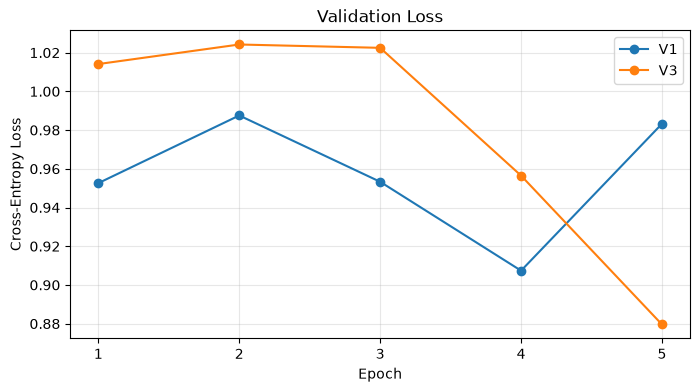

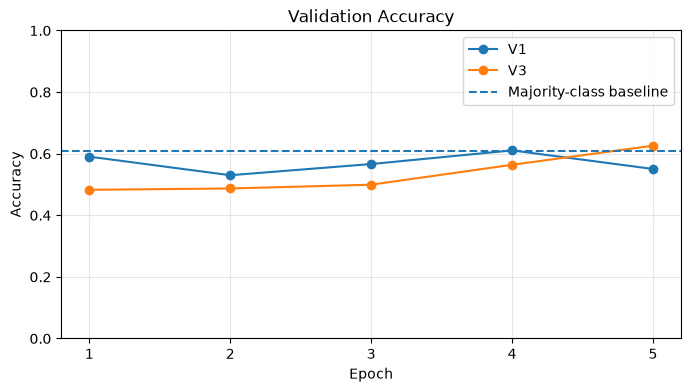

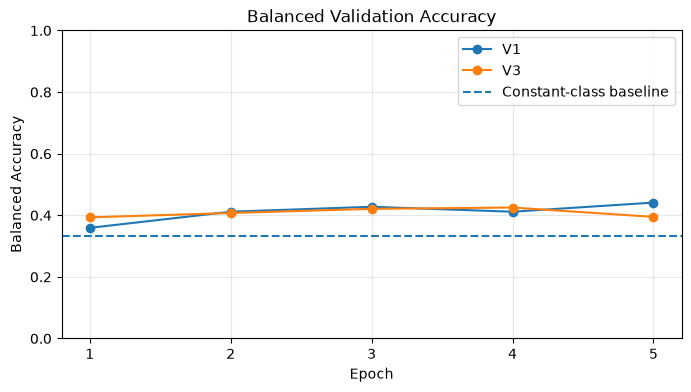

In [20]:

import matplotlib.pyplot as plt

# Extract epoch numbers and metrics from our histories.
epochs_v1 = [entry["epoch"] for entry in history_v1]
epochs_v3 = [entry["epoch"] for entry in history_v3]


def get_metric(history, metric):
    """Extract one metric across all recorded epochs."""
    return [entry[metric] for entry in history]


# Figure 1: Validation loss
plt.figure(figsize=(8, 4))

plt.plot(
    epochs_v1,
    get_metric(history_v1, "val_loss"),
    marker="o",
    label="V1"
)

plt.plot(
    epochs_v3,
    get_metric(history_v3, "val_loss"),
    marker="o",
    label="V3"
)

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(epochs_v1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Figure 2: Overall validation accuracy
plt.figure(figsize=(8, 4))

plt.plot(
    epochs_v1,
    get_metric(history_v1, "val_accuracy"),
    marker="o",
    label="V1"
)

plt.plot(
    epochs_v3,
    get_metric(history_v3, "val_accuracy"),
    marker="o",
    label="V3"
)

# Accuracy of a classifier that always predicts happy.
majority_baseline = max(
    np.bincount(y_val)
) / len(y_val)

plt.axhline(
    majority_baseline,
    linestyle="--",
    label="Majority-class baseline"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs_v1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# Figure 3: Balanced accuracy
plt.figure(figsize=(8, 4))

plt.plot(
    epochs_v1,
    get_metric(history_v1, "balanced_accuracy"),
    marker="o",
    label="V1"
)

plt.plot(
    epochs_v3,
    get_metric(history_v3, "balanced_accuracy"),
    marker="o",
    label="V3"
)

# Balanced accuracy of a constant-class classifier.
chance_baseline = 1 / len(loader.CLASS_NAMES)

plt.axhline(
    chance_baseline,
    linestyle="--",
    label="Constant-class baseline"
)

plt.title("Balanced Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Balanced Accuracy")
plt.xticks(epochs_v1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()



## 7. Model Checkpointing

### 7.1 Preserving Trained Models

Neural-network training modifies the model's weights
and biases after every mini-batch.

We save checkpoints to preserve training progress and
allow experiments to resume without starting over.

Each checkpoint contains:

- Trainable weights and biases
- Completed epoch number
- Training and validation metric history
- Random-number generator state
- Training hyperparameters

We use NumPy's compressed NPZ format to store model
parameters and metadata.

Future checkpoints will be selected primarily using
validation balanced accuracy.

These initial checkpoints preserve the models at epoch 5.


In [21]:

import json
from pathlib import Path

# Create a directory for saved models.
checkpoint_dir = Path.cwd() / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)


def json_converter(value):
    """Convert NumPy values to JSON-compatible values."""

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    raise TypeError(f"Cannot serialize {type(value)}")


def save_checkpoint(model, history, rng, name):

    epoch = history[-1]["epoch"]

    # Collect trainable parameters.
    parameters = {}

    dense_layers = [
        layer for layer in model.layers
        if isinstance(layer, Dense)
    ]

    for i, layer in enumerate(dense_layers):
        parameters[f"weights_{i}"] = layer.weights.copy()
        parameters[f"bias_{i}"] = layer.bias.copy()

    # Store information needed to resume training.
    metadata = {
        "epoch": epoch,
        "history": history,
        "rng_state": rng.bit_generator.state,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "architecture": [2304, 128, 3],
        "classes": list(loader.CLASS_NAMES),
    }

    parameters["metadata"] = np.array(
        json.dumps(metadata, default=json_converter)
    )

    path = checkpoint_dir / f"{name}_epoch_{epoch:02d}.npz"

    np.savez_compressed(path, **parameters)

    return path


# Save both experiments.
path_v1 = save_checkpoint(
    model_v1, history_v1, rng_v1, "baseline_v1"
)

path_v3 = save_checkpoint(
    model_v3, history_v3, rng_v3, "baseline_v3"
)

# Verify saved files can be read.
for path in (path_v1, path_v3):

    with np.load(path, allow_pickle=False) as saved:
        metadata = json.loads(saved["metadata"].item())

        assert metadata["epoch"] == 5
        assert saved["weights_0"].shape == (2304, 128)
        assert saved["weights_1"].shape == (128, 3)

    print(f"Saved and verified: {path}")

print("\nBoth epoch-5 checkpoints saved successfully.")


Saved and verified: C:\Users\mashe\code\class\Capstone-DATA4381\Model_Revisions\checkpoints\baseline_v1_epoch_05.npz
Saved and verified: C:\Users\mashe\code\class\Capstone-DATA4381\Model_Revisions\checkpoints\baseline_v3_epoch_05.npz

Both epoch-5 checkpoints saved successfully.



### 7.2 Automatic Best-Model Checkpointing

We continue training both experiments from epoch 6
through epoch 10.

After each epoch, we evaluate the models on our cleaned
validation dataset.

We use balanced validation accuracy as our primary
checkpoint-selection metric because the validation
dataset contains substantially more happy images than
angry or sad images.

Whenever a model achieves a higher balanced accuracy
than its best previously saved checkpoint, we save
its updated parameters and training state.

We also save the latest checkpoint at epoch 10,
regardless of performance, to support continued training.

**Note:** V3's epoch-4 weights were not saved. Therefore,
automatic checkpoint selection begins with the available
epoch-5 models.

These remain exploratory experiments because potential
near-duplicate and augmentation-source leakage has not
been completely excluded.


In [22]:

# Verify both models are currently at epoch 5.
assert history_v1[-1]["epoch"] == 5
assert history_v3[-1]["epoch"] == 5

assert len(history_v1) == 5
assert len(history_v3) == 5


# Track the best checkpoints currently available.
best_saved = {
    "V1": {
        "score": history_v1[-1]["balanced_accuracy"],
        "epoch": 5,
        "path": path_v1,
    },
    "V3": {
        "score": history_v3[-1]["balanced_accuracy"],
        "epoch": 5,
        "path": path_v3,
    },
}


experiments = [
    ("V1", model_v1, X_train_v1, y_train_v1,
     rng_v1, history_v1),

    ("V3", model_v3, X_train_v3, y_train_v3,
     rng_v3, history_v3),
]


# Continue training from epoch 6 through epoch 10.
for epoch in range(6, 11):

    print(f"\nEPOCH {epoch}")
    print("=" * 55)

    for name, model, X_train, y_train, rng, history in experiments:

        # Train one epoch.
        train_metrics = train_epoch(
            model=model,
            X=X_train,
            y=y_train,
            batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE,
            rng=rng,
        )

        # Evaluate validation performance.
        val_metrics = evaluate(
            model,
            X_val,
            y_val,
            batch_size=BATCH_SIZE,
        )

        balanced_acc, recalls = validation_recalls(
            model,
            X_val,
            y_val,
        )

        # Record results.
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "balanced_accuracy": balanced_acc,
            "recalls": recalls.copy(),
        })

        # Save if balanced accuracy improves.
        if balanced_acc > best_saved[name]["score"]:

            path = save_checkpoint(
                model,
                history,
                rng,
                f"baseline_{name.lower()}_best",
            )

            best_saved[name] = {
                "score": balanced_acc,
                "epoch": epoch,
                "path": path,
            }

            print(f"\n  {name}: New best checkpoint saved!")

        # Display metrics.
        print(f"\n{name}")
        print(f"  Train loss:   {train_metrics['loss']:.4f}")
        print(f"  Train acc:    {train_metrics['accuracy']:.2%}")
        print(f"  Val loss:     {val_metrics['loss']:.4f}")
        print(f"  Val acc:      {val_metrics['accuracy']:.2%}")
        print(f"  Balanced acc: {balanced_acc:.2%}")

        print("  Per-class recall:")

        for class_name, recall in recalls.items():
            print(f"    {class_name:<8}: {recall:.2%}")


# Save the latest state at epoch 10.
latest_v1 = save_checkpoint(
    model_v1, history_v1, rng_v1, "baseline_v1"
)

latest_v3 = save_checkpoint(
    model_v3, history_v3, rng_v3, "baseline_v3"
)


print("\nBEST AVAILABLE CHECKPOINTS")
print("=" * 55)

for name, result in best_saved.items():
    print(
        f"{name}: Epoch {result['epoch']} | "
        f"Balanced accuracy: {result['score']:.2%}"
    )

print("\nEpoch-10 checkpoints saved.")



EPOCH 6

V1
  Train loss:   0.9064
  Train acc:    54.77%
  Val loss:     0.9109
  Val acc:      60.64%
  Balanced acc: 40.68%
  Per-class recall:
    angry   : 9.91%
    happy   : 91.03%
    sad     : 21.11%

  V3: New best checkpoint saved!

V3
  Train loss:   1.0201
  Train acc:    48.83%
  Val loss:     0.9730
  Val acc:      54.92%
  Balanced acc: 44.19%
  Per-class recall:
    angry   : 57.49%
    happy   : 61.19%
    sad     : 13.89%

EPOCH 7

  V1: New best checkpoint saved!

V1
  Train loss:   0.8991
  Train acc:    55.14%
  Val loss:     0.9474
  Val acc:      58.61%
  Balanced acc: 44.89%
  Per-class recall:
    angry   : 28.41%
    happy   : 77.92%
    sad     : 28.33%

  V3: New best checkpoint saved!

V3
  Train loss:   1.0137
  Train acc:    49.40%
  Val loss:     0.9469
  Val acc:      58.06%
  Balanced acc: 45.50%
  Per-class recall:
    angry   : 50.22%
    happy   : 69.05%
    sad     : 17.22%

EPOCH 8

V1
  Train loss:   0.8926
  Train acc:    55.70%
  Val loss:   


### 7.3 Per-Class Recall Analysis

After ten epochs, both models show substantial differences
in their ability to recognize individual emotions.

V1 achieves higher overall validation accuracy but
continues to favor the happy class.

V3 achieves higher balanced accuracy at epoch 10,
with better recognition of angry and sad expressions.

We visualize per-class recall across training epochs
to determine whether these differences are persistent
or reflect short-term fluctuations.

This analysis will inform our decision to continue
training without modifying the model architecture.


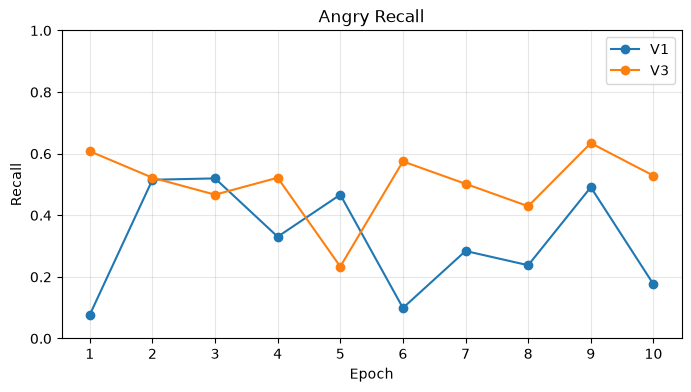

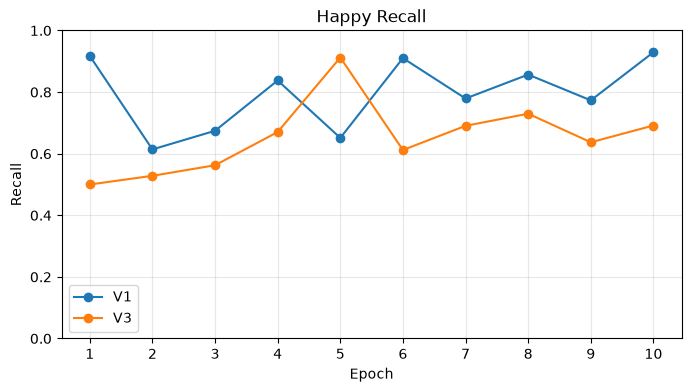

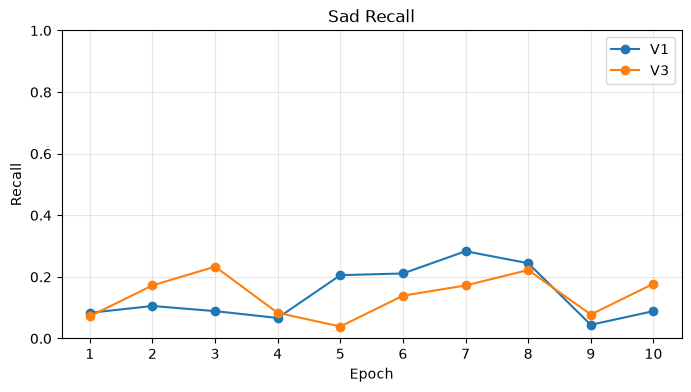

In [23]:

import matplotlib.pyplot as plt

# Plot recall for each emotion separately.
for class_name in loader.CLASS_NAMES:

    plt.figure(figsize=(8, 4))

    for name, history in [
        ("V1", history_v1),
        ("V3", history_v3),
    ]:

        epochs = [
            entry["epoch"]
            for entry in history
        ]

        recalls = [
            entry["recalls"][class_name]
            for entry in history
        ]

        plt.plot(
            epochs,
            recalls,
            marker="o",
            label=name,
        )

    plt.title(f"{class_name.capitalize()} Recall")
    plt.xlabel("Epoch")
    plt.ylabel("Recall")
    plt.xticks(range(1, 11))
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()



### 7.4 Continued Training — Epochs 11–15

The first ten epochs reveal substantial fluctuations in
per-class recall, particularly for angry and sad expressions.

Although both models demonstrate learning, neither has
achieved consistently strong performance across all classes.

We continue training through epoch 15 without changing
the architecture or hyperparameters.

This allows us to determine whether additional training
improves class recognition and stabilizes validation
performance.

We continue using balanced validation accuracy for
checkpoint selection and preserve the latest model
states for subsequent experiments.


In [24]:

# Verify our current training progress.
assert history_v1[-1]["epoch"] == 10
assert history_v3[-1]["epoch"] == 10

assert len(history_v1) == 10
assert len(history_v3) == 10


experiments = [
    ("V1", model_v1, X_train_v1, y_train_v1,
     rng_v1, history_v1),

    ("V3", model_v3, X_train_v3, y_train_v3,
     rng_v3, history_v3),
]


for epoch in range(11, 16):

    print(f"\nEPOCH {epoch}")
    print("=" * 55)

    for name, model, X_train, y_train, rng, history in experiments:

        # Train for one epoch.
        train_metrics = train_epoch(
            model=model,
            X=X_train,
            y=y_train,
            batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE,
            rng=rng,
        )

        # Evaluate on validation images.
        val_metrics = evaluate(
            model,
            X_val,
            y_val,
            batch_size=BATCH_SIZE,
        )

        balanced_acc, recalls = validation_recalls(
            model,
            X_val,
            y_val,
        )

        # Record the epoch's results.
        history.append({
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "balanced_accuracy": balanced_acc,
            "recalls": recalls.copy(),
        })

        # Save new best models.
        if balanced_acc > best_saved[name]["score"]:

            path = save_checkpoint(
                model,
                history,
                rng,
                f"baseline_{name.lower()}_best",
            )

            best_saved[name] = {
                "score": balanced_acc,
                "epoch": epoch,
                "path": path,
            }

            print(f"\n{name}: New best checkpoint saved!")

        print(f"\n{name}")
        print(f"  Train loss:   {train_metrics['loss']:.4f}")
        print(f"  Train acc:    {train_metrics['accuracy']:.2%}")
        print(f"  Val loss:     {val_metrics['loss']:.4f}")
        print(f"  Val acc:      {val_metrics['accuracy']:.2%}")
        print(f"  Balanced acc: {balanced_acc:.2%}")

        print("  Class recall:")

        for class_name, recall in recalls.items():
            print(f"    {class_name:<8}: {recall:.2%}")


# Save the latest models at epoch 15.
latest_v1 = save_checkpoint(
    model_v1, history_v1, rng_v1, "baseline_v1"
)

latest_v3 = save_checkpoint(
    model_v3, history_v3, rng_v3, "baseline_v3"
)


print("\nBEST AVAILABLE CHECKPOINTS")
print("=" * 55)

for name, result in best_saved.items():

    print(
        f"{name}: Epoch {result['epoch']} | "
        f"Balanced accuracy: {result['score']:.2%}"
    )

print("\nEpoch-15 checkpoints saved.")



EPOCH 11

V1: New best checkpoint saved!

V1
  Train loss:   0.8786
  Train acc:    56.39%
  Val loss:     0.9119
  Val acc:      61.56%
  Balanced acc: 46.80%
  Class recall:
    angry   : 32.60%
    happy   : 81.15%
    sad     : 26.67%

V3
  Train loss:   0.9959
  Train acc:    51.27%
  Val loss:     0.8979
  Val acc:      61.50%
  Balanced acc: 46.00%
  Class recall:
    angry   : 48.46%
    happy   : 76.21%
    sad     : 13.33%

EPOCH 12

V1
  Train loss:   0.8741
  Train acc:    56.82%
  Val loss:     0.8571
  Val acc:      63.65%
  Balanced acc: 43.51%
  Class recall:
    angry   : 32.38%
    happy   : 87.60%
    sad     : 10.56%

V3
  Train loss:   0.9924
  Train acc:    51.56%
  Val loss:     0.8795
  Val acc:      63.53%
  Balanced acc: 46.45%
  Class recall:
    angry   : 42.29%
    happy   : 82.06%
    sad     : 15.00%

EPOCH 13

V1
  Train loss:   0.8707
  Train acc:    57.10%
  Val loss:     0.8683
  Val acc:      63.28%
  Balanced acc: 45.61%
  Class recall:
    angry  


### 7.5 Confusion Matrix Analysis

After 15 training epochs, we examine the confusion matrices
for both neural networks.

A confusion matrix compares actual class labels against
predicted class labels.

Rows represent the true emotion, while columns represent
the predicted emotion.

The diagonal contains correctly classified images.
Off-diagonal entries represent classification errors.

We also normalize each row to examine how frequently
each emotion is classified correctly or confused with
another emotion.

This helps identify the specific classification mistakes
that are not visible from overall accuracy alone.

The analysis uses the validation dataset and does not
modify model parameters.


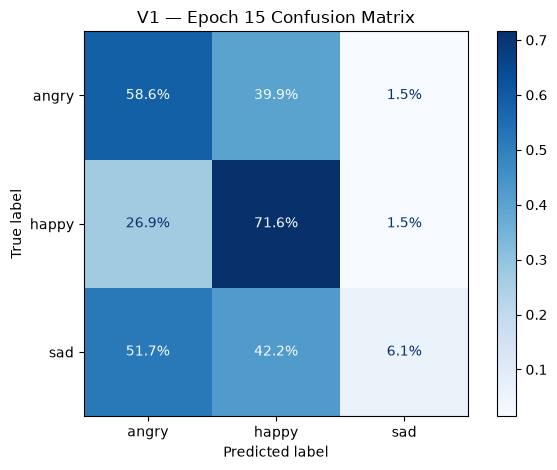


V1 — Predicted class distribution
  angry   : 626 (38.50%)
  happy   : 967 (59.47%)
  sad     : 33 (2.03%)


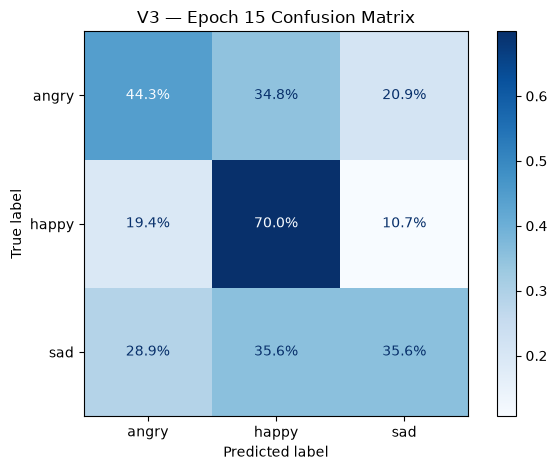


V3 — Predicted class distribution
  angry   : 445 (27.37%)
  happy   : 916 (56.33%)
  sad     : 265 (16.30%)


In [25]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt


def predict_classes(model, X, batch_size=256):
    """Generate class predictions in mini-batches."""

    predictions = []

    for start in range(0, len(X), batch_size):

        batch = X[start:start + batch_size]

        logits = model.forward(batch)

        predictions.append(
            np.argmax(logits, axis=1)
        )

    return np.concatenate(predictions)


# Evaluate both models at epoch 15.
models = {
    "V1": model_v1,
    "V3": model_v3,
}

for name, model in models.items():

    y_pred = predict_classes(model, X_val)

    # Normalize each row by its true-class count.
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=range(len(loader.CLASS_NAMES)),
        normalize="true",
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=loader.CLASS_NAMES,
    )

    display.plot(
        cmap="Blues",
        values_format=".1%",
    )

    plt.title(f"{name} — Epoch 15 Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # Examine prediction frequencies.
    predicted_counts = np.bincount(
        y_pred,
        minlength=len(loader.CLASS_NAMES),
    )

    print(f"\n{name} — Predicted class distribution")

    for class_name, count in zip(
        loader.CLASS_NAMES,
        predicted_counts,
    ):
        print(
            f"  {class_name:<8}: "
            f"{count:,} ({count / len(y_pred):.2%})"
        )



### 7.6 Continued Training — Epochs 16–20

The epoch-15 confusion matrices reveal substantial
differences in how the two models classify emotions.

V1 rarely predicts sad, resulting in extremely low
sad recall.

V3 identifies more sad expressions but also produces
more incorrect sad predictions.

We continue training both models without changing
the architecture, learning rate, or batch size.

We preserve the best model according to validation
balanced accuracy and save the latest training state
at epoch 20.

This maintains consistency with our original baseline
experiment and allows us to examine whether additional
training improves class recognition.


In [26]:

def continue_experiments(start_epoch, end_epoch):

    experiments = [
        ("V1", model_v1, X_train_v1, y_train_v1,
         rng_v1, history_v1),

        ("V3", model_v3, X_train_v3, y_train_v3,
         rng_v3, history_v3),
    ]

    # Prevent accidentally repeating completed epochs.
    for name, model, X_train, y_train, rng, history in experiments:
        assert history[-1]["epoch"] == start_epoch - 1, (
            f"{name} is at epoch {history[-1]['epoch']}, "
            f"not epoch {start_epoch - 1}"
        )

    for epoch in range(start_epoch, end_epoch + 1):

        print(f"\nEPOCH {epoch}")
        print("=" * 55)

        for name, model, X_train, y_train, rng, history in experiments:

            train_metrics = train_epoch(
                model=model,
                X=X_train,
                y=y_train,
                batch_size=BATCH_SIZE,
                learning_rate=LEARNING_RATE,
                rng=rng,
            )

            val_metrics = evaluate(
                model,
                X_val,
                y_val,
                batch_size=BATCH_SIZE,
            )

            balanced_acc, recalls = validation_recalls(
                model,
                X_val,
                y_val,
            )

            history.append({
                "epoch": epoch,
                "train_loss": train_metrics["loss"],
                "train_accuracy": train_metrics["accuracy"],
                "val_loss": val_metrics["loss"],
                "val_accuracy": val_metrics["accuracy"],
                "balanced_accuracy": balanced_acc,
                "recalls": recalls.copy(),
            })

            # Preserve new best checkpoints.
            if balanced_acc > best_saved[name]["score"]:

                path = save_checkpoint(
                    model,
                    history,
                    rng,
                    f"baseline_{name.lower()}_best",
                )

                best_saved[name] = {
                    "score": balanced_acc,
                    "epoch": epoch,
                    "path": path,
                }

                print(f"{name}: New best checkpoint saved!")

            print(f"\n{name}")
            print(f"  Train loss:   {train_metrics['loss']:.4f}")
            print(f"  Train acc:    {train_metrics['accuracy']:.2%}")
            print(f"  Val loss:     {val_metrics['loss']:.4f}")
            print(f"  Val acc:      {val_metrics['accuracy']:.2%}")
            print(f"  Balanced acc: {balanced_acc:.2%}")

            print("  Per-class recall:")

            for class_name, recall in recalls.items():
                print(f"    {class_name:<8}: {recall:.2%}")

    # Save latest models for resuming training.
    for name, model, X_train, y_train, rng, history in experiments:

        save_checkpoint(
            model,
            history,
            rng,
            f"baseline_{name.lower()}",
        )

    print("\nBEST AVAILABLE CHECKPOINTS")
    print("=" * 55)

    for name, result in best_saved.items():
        print(
            f"{name}: Epoch {result['epoch']} | "
            f"Balanced accuracy: {result['score']:.2%}"
        )

    print(f"\nEpoch-{end_epoch} checkpoints saved.")


# Continue from epoch 15 to epoch 20.
continue_experiments(16, 20)



EPOCH 16

V1
  Train loss:   0.8618
  Train acc:    57.46%
  Val loss:     0.8444
  Val acc:      62.92%
  Balanced acc: 41.33%
  Per-class recall:
    angry   : 20.04%
    happy   : 91.73%
    sad     : 12.22%

V3
  Train loss:   0.9790
  Train acc:    52.93%
  Val loss:     0.8786
  Val acc:      63.84%
  Balanced acc: 48.83%
  Per-class recall:
    angry   : 43.61%
    happy   : 80.65%
    sad     : 22.22%

EPOCH 17
V1: New best checkpoint saved!

V1
  Train loss:   0.8584
  Train acc:    57.62%
  Val loss:     0.8718
  Val acc:      63.96%
  Balanced acc: 48.10%
  Per-class recall:
    angry   : 44.27%
    happy   : 81.15%
    sad     : 18.89%

V3
  Train loss:   0.9765
  Train acc:    52.72%
  Val loss:     0.8858
  Val acc:      61.62%
  Balanced acc: 48.21%
  Per-class recall:
    angry   : 59.47%
    happy   : 71.27%
    sad     : 13.89%

EPOCH 18

V1
  Train loss:   0.8552
  Train acc:    58.09%
  Val loss:     0.8680
  Val acc:      63.53%
  Balanced acc: 47.61%
  Per-class 


### 7.7 Final Training — Epochs 21–30

We complete the remaining ten epochs of both baseline
experiments using unchanged hyperparameters.

Training continues from the existing epoch-20 models.

Automatic checkpointing preserves the best validation
balanced accuracy, while final checkpoints retain the
epoch-30 model states.

After training, we compare learning curves, class recall,
and the best-performing checkpoints for both experiments.


In [27]:

# Complete both baseline experiments.
continue_experiments(21, 30)



EPOCH 21

V1
  Train loss:   0.8490
  Train acc:    58.68%
  Val loss:     0.8426
  Val acc:      64.02%
  Balanced acc: 46.08%
  Per-class recall:
    angry   : 42.95%
    happy   : 83.06%
    sad     : 12.22%
V3: New best checkpoint saved!

V3
  Train loss:   0.9663
  Train acc:    53.79%
  Val loss:     0.9244
  Val acc:      59.96%
  Balanced acc: 51.84%
  Per-class recall:
    angry   : 62.78%
    happy   : 64.42%
    sad     : 28.33%

EPOCH 22
V1: New best checkpoint saved!

V1
  Train loss:   0.8466
  Train acc:    58.85%
  Val loss:     0.8910
  Val acc:      61.75%
  Balanced acc: 49.20%
  Per-class recall:
    angry   : 57.05%
    happy   : 71.67%
    sad     : 18.89%

V3
  Train loss:   0.9645
  Train acc:    54.12%
  Val loss:     0.9073
  Val acc:      60.95%
  Balanced acc: 51.26%
  Per-class recall:
    angry   : 56.61%
    happy   : 68.85%
    sad     : 28.33%

EPOCH 23

V1
  Train loss:   0.8442
  Train acc:    59.15%
  Val loss:     0.8643
  Val acc:      63.10%
  Ba


## 8. Best Model Evaluation

### 8.1 Restoring the Best Validation Checkpoints

Both augmentation experiments completed 30 training epochs.

The highest validation balanced accuracy for both models
occurred at epoch 24:

- V1: 50.23%
- V3: 52.21%

We restore these saved model parameters into separate
neural-network instances.

This preserves the epoch-30 models while allowing us
to compare the best validation checkpoints.

We calculate validation loss, overall accuracy,
balanced accuracy, and per-class recall.

The test dataset remains reserved for final evaluation.
These validation results are used for model selection
and should not be interpreted as unbiased test performance.


In [28]:

# Restore a model from one of our saved checkpoints.
def restore_model(path):

    model = build_baseline(seed=42)

    dense_layers = [
        layer for layer in model.layers
        if isinstance(layer, Dense)
    ]

    with np.load(path, allow_pickle=False) as saved:

        metadata = json.loads(
            saved["metadata"].item()
        )

        for i, layer in enumerate(dense_layers):

            weights = saved[f"weights_{i}"]
            biases = saved[f"bias_{i}"]

            assert weights.shape == layer.weights.shape
            assert biases.shape == layer.bias.shape

            layer.weights[:] = weights
            layer.bias[:] = biases

    return model, metadata


# Restore the best checkpoints without changing
# our existing epoch-30 models.
best_model_v1, metadata_v1 = restore_model(
    best_saved["V1"]["path"]
)

best_model_v3, metadata_v3 = restore_model(
    best_saved["V3"]["path"]
)


# Compare both models on our validation dataset.
for name, model, metadata in [
    ("V1", best_model_v1, metadata_v1),
    ("V3", best_model_v3, metadata_v3),
]:

    metrics = evaluate(
        model,
        X_val,
        y_val,
        batch_size=BATCH_SIZE,
    )

    balanced_acc, recalls = validation_recalls(
        model,
        X_val,
        y_val,
    )

    print(f"\n{name} — BEST CHECKPOINT")
    print("=" * 45)

    print("Epoch:", metadata["epoch"])
    print(f"Validation loss: {metrics['loss']:.4f}")
    print(f"Validation accuracy: {metrics['accuracy']:.2%}")
    print(f"Balanced accuracy: {balanced_acc:.2%}")

    print("\nPer-class recall:")

    for class_name, recall in recalls.items():
        print(f"  {class_name:<8}: {recall:.2%}")



V1 — BEST CHECKPOINT
Epoch: 24
Validation loss: 0.9101
Validation accuracy: 60.46%
Balanced accuracy: 50.23%

Per-class recall:
  angry   : 59.91%
  happy   : 67.44%
  sad     : 23.33%

V3 — BEST CHECKPOINT
Epoch: 24
Validation loss: 0.9145
Validation accuracy: 60.64%
Balanced accuracy: 52.21%

Per-class recall:
  angry   : 66.96%
  happy   : 64.11%
  sad     : 25.56%



### 8.2 Classification Performance of Selected Checkpoints

We evaluate the best validation checkpoints from both
augmentation experiments.

Both models were selected at epoch 24 based on their
validation balanced accuracy.

We examine:

- **Precision:** Of the images predicted as a particular
  emotion, how many were correctly classified?
- **Recall:** Of the images actually belonging to an
  emotion, how many were correctly classified?
- **F1-score:** The harmonic mean of precision and recall.
- **Confusion matrix:** Shows how predictions are
  distributed across the three emotions.

These metrics provide a more complete assessment than
overall accuracy alone, particularly because the
validation dataset is imbalanced.

The test dataset remains reserved for final evaluation.



V1 — BEST CHECKPOINT
              precision    recall  f1-score   support

       angry     0.4387    0.5991    0.5065       454
       happy     0.7672    0.6744    0.7178       992
         sad     0.3134    0.2333    0.2675       180

    accuracy                         0.6046      1626
   macro avg     0.5064    0.5023    0.4973      1626
weighted avg     0.6252    0.6046    0.6090      1626



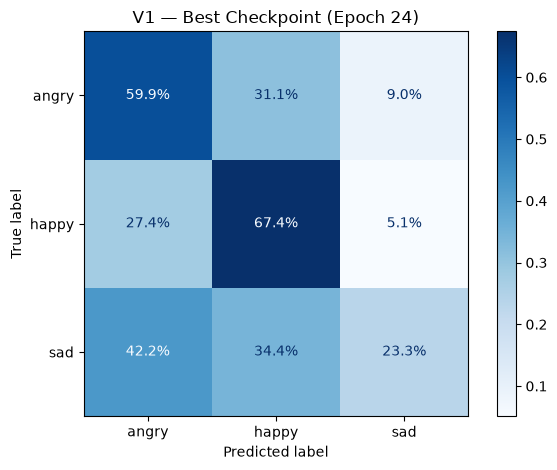


V3 — BEST CHECKPOINT
              precision    recall  f1-score   support

       angry     0.4368    0.6696    0.5287       454
       happy     0.7940    0.6411    0.7094       992
         sad     0.3566    0.2556    0.2977       180

    accuracy                         0.6064      1626
   macro avg     0.5291    0.5221    0.5120      1626
weighted avg     0.6458    0.6064    0.6134      1626



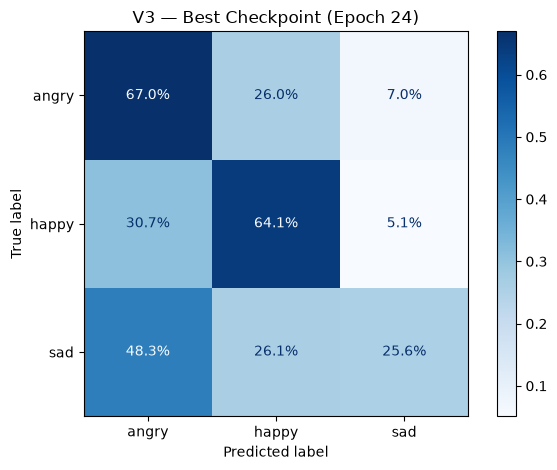

In [29]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
import matplotlib.pyplot as plt

# Evaluate our selected epoch-24 models.
best_models = {
    "V1": best_model_v1,
    "V3": best_model_v3,
}

for name, model in best_models.items():

    # Generate predictions using the restored weights.
    y_pred = predict_classes(
        model,
        X_val,
        batch_size=256,
    )

    print(f"\n{name} — BEST CHECKPOINT")
    print("=" * 55)

    # Precision, recall, and F1-score.
    print(
        classification_report(
            y_val,
            y_pred,
            labels=range(len(loader.CLASS_NAMES)),
            target_names=loader.CLASS_NAMES,
            digits=4,
            zero_division=0,
        )
    )

    # Generate a row-normalized confusion matrix.
    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=range(len(loader.CLASS_NAMES)),
        normalize="true",
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=loader.CLASS_NAMES,
    )

    display.plot(
        cmap="Blues",
        values_format=".1%",
    )

    plt.title(
        f"{name} — Best Checkpoint (Epoch 24)"
    )

    plt.tight_layout()
    plt.show()



## 9. Final Training Analysis

### 9.1 Thirty-Epoch Learning Curves

Both baseline models completed 30 epochs of training.

We compare their training and validation loss, overall
validation accuracy, and balanced validation accuracy.

The best checkpoints for both models occurred at epoch 24,
based on balanced validation accuracy.

We mark this epoch on the learning curves to illustrate
why checkpoint selection is preferable to simply using
the final epoch.

These visualizations help identify convergence behavior,
training instability, and possible overfitting.

Our evaluation remains provisional pending completion of
the dataset leakage audit.


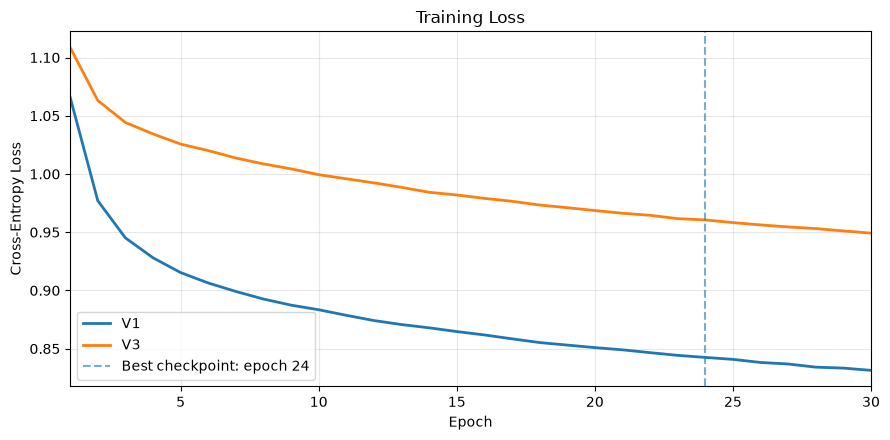

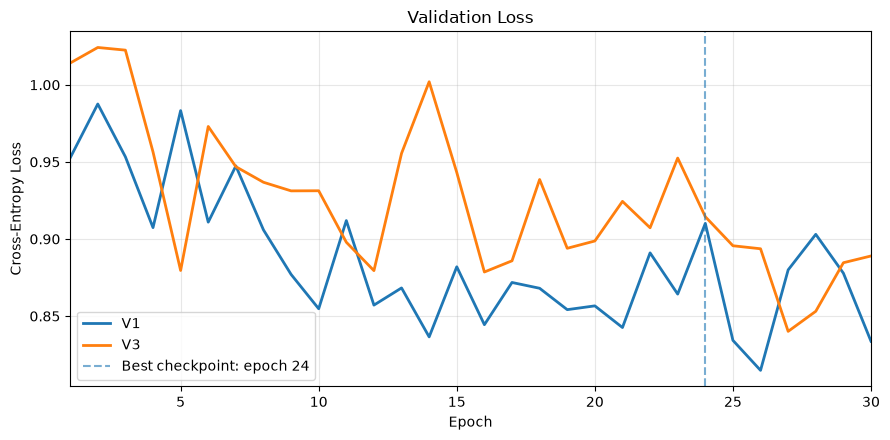

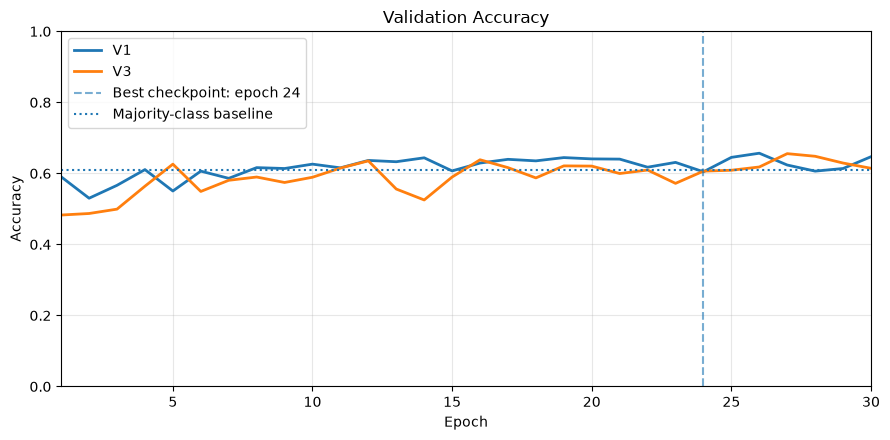

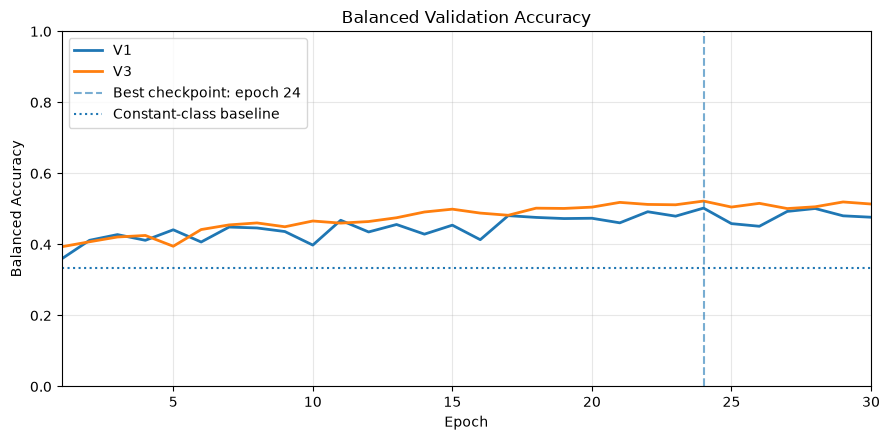

In [30]:

import matplotlib.pyplot as plt

histories = {
    "V1": history_v1,
    "V3": history_v3,
}

# Verify that both experiments completed 30 epochs.
for name, history in histories.items():
    assert len(history) == 30
    assert history[-1]["epoch"] == 30


# Metrics to visualize.
plots = [
    ("train_loss", "Training Loss", "Cross-Entropy Loss"),
    ("val_loss", "Validation Loss", "Cross-Entropy Loss"),
    ("val_accuracy", "Validation Accuracy", "Accuracy"),
    ("balanced_accuracy", "Balanced Validation Accuracy",
     "Balanced Accuracy"),
]


for metric, title, ylabel in plots:

    plt.figure(figsize=(9, 4.5))

    for name, history in histories.items():

        epochs = [
            entry["epoch"] for entry in history
        ]

        values = [
            entry[metric] for entry in history
        ]

        plt.plot(
            epochs,
            values,
            label=name,
            linewidth=2,
        )

    # Both models achieved their best balanced
    # validation accuracy at epoch 24.
    plt.axvline(
        x=24,
        linestyle="--",
        alpha=0.6,
        label="Best checkpoint: epoch 24",
    )

    # Add appropriate reference baselines.
    if metric == "val_accuracy":

        majority_baseline = (
            np.bincount(y_val).max() / len(y_val)
        )

        plt.axhline(
            majority_baseline,
            linestyle=":",
            label="Majority-class baseline",
        )

    elif metric == "balanced_accuracy":

        plt.axhline(
            1 / len(loader.CLASS_NAMES),
            linestyle=":",
            label="Constant-class baseline",
        )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.xlim(1, 30)

    if "accuracy" in metric:
        plt.ylim(0, 1)

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()



### 9.2 Training Analysis and Experimental Findings

Both baseline neural networks completed 30 epochs of
training using identical architectures and hyperparameters.

**Convergence**

Training loss decreased consistently for both models,
indicating successful optimization. V1 achieved lower
training loss throughout the experiment.

**Generalization**

Validation loss fluctuated across epochs but generally
decreased over the training period. Neither experiment
exhibited a clear, sustained increase in validation loss
that would indicate severe overfitting.

**Classification Performance**

Overall validation accuracy plateaued near 60–65%.
Because the validation dataset is imbalanced, overall
accuracy alone provides an incomplete measure of
classification performance.

Balanced validation accuracy improved for both models.
V3 generally performed better on this metric during
later epochs.

**Best Checkpoints**

Both models achieved their highest recorded validation
balanced accuracy at epoch 24:

- V1: 50.23%
- V3: 52.21%

V3 also achieved a higher macro F1-score:

- V1: 49.73%
- V3: 51.20%

**Limitations**

Both models struggled to recognize sad expressions.
The fully connected architecture does not explicitly
preserve spatial relationships between facial features.

The experiments were conducted using a single random
initialization per augmentation strategy, and differences
have not been tested for statistical significance.

**Conclusion**

Augmentation V3 produced modestly better class-balanced
validation performance than V1 for this baseline network.

These findings remain provisional until dataset integrity
checks and final held-out test evaluation are completed.



## 10. Comparison with Original Baseline Models

### 10.1 Original Neural Network vs. Augmented Models

The original neural-network baseline is documented in
`Baseline_Models/NN_baseline.ipynb`.

It uses a NumPy implementation of a fully connected
neural network with one hidden layer of 128 neurons.

The revised V1 and V3 models preserve the same general
architecture, optimizer, batch size, learning rate, and
30-epoch training schedule.

Key differences include:

- The original baseline classifies four emotions.
- The revised models classify three emotions.
- The original baseline uses an 80/20 train/test split.
- The revised models use predefined train/validation/test
  partitions and training-only augmentation.
- The revised models are selected using validation
  balanced accuracy.

We compare accuracy, balanced accuracy, macro F1-score,
and per-class recall.

**Important:** This is a historical comparison, not a
controlled experiment. The models use different class
sets and evaluation partitions, so differences cannot
be attributed solely to augmentation.


In [31]:

import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report

# Historical results from Baseline_Models/NN_baseline.ipynb
results = [{
    "Model": "Original NN",
    "Classes": 4,
    "Partition": "Test",
    "Accuracy": 0.4880,
    "Balanced accuracy": 0.3338,
    "Macro F1": 0.3006,
    "Angry recall": 0.1036,
    "Happy recall": 0.9499,
    "Sad recall": 0.0201,
    "Majority baseline": 1336 / 3365,
}]

# Calculate metrics for the selected augmented models.
for name, model in [
    ("NN V1", best_model_v1),
    ("NN V3", best_model_v3),
]:

    predictions = predict_classes(model, X_val)

    report = classification_report(
        y_val,
        predictions,
        labels=range(len(loader.CLASS_NAMES)),
        target_names=loader.CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )

    results.append({
        "Model": name,
        "Classes": len(loader.CLASS_NAMES),
        "Partition": "Validation",
        "Accuracy": report["accuracy"],
        "Balanced accuracy": report["macro avg"]["recall"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Angry recall": report["angry"]["recall"],
        "Happy recall": report["happy"]["recall"],
        "Sad recall": report["sad"]["recall"],
        "Majority baseline": (
            np.bincount(y_val).max() / len(y_val)
        ),
    })

comparison_df = pd.DataFrame(results)

percentage_columns = [
    "Accuracy",
    "Balanced accuracy",
    "Macro F1",
    "Angry recall",
    "Happy recall",
    "Sad recall",
    "Majority baseline",
]

display(
    comparison_df.style.format({
        column: "{:.2%}"
        for column in percentage_columns
    })
)


,Model,Classes,Partition,Accuracy,Balanced accuracy,Macro F1,Angry recall,Happy recall,Sad recall,Majority baseline
0,Original NN,4,Test,48.80%,33.38%,30.06%,10.36%,94.99%,2.01%,39.70%
1,NN V1,3,Validation,60.46%,50.23%,49.73%,59.91%,67.44%,23.33%,61.01%
2,NN V3,3,Validation,60.64%,52.21%,51.20%,66.96%,64.11%,25.56%,61.01%
